In [ ]:

import pandas as pd
import zipfile
import urllib.request
import os

# Download the dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"

urllib.request.urlretrieve(url, "spam_dataset.zip")

# Extract the downloaded ZIP file
with zipfile.ZipFile("spam_dataset.zip", "r") as zip_file:
    zip_file.extractall("spam_data")

# Read the dataset
file_path = "spam_data/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["Label", "Message"],
    encoding="utf-8"
)

# Display the first five rows
df.head()


,Label,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:

# Number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns)

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count spam and non-spam messages
print("\nMessage categories:")
print(df["Label"].value_counts())

# Display sample messages
display(df.head(10))


Dataset shape: (5572, 2)

Column names:
Index(['Label', 'Message'], dtype='object')

Missing values:
Label      0
Message    0
dtype: int64

Message categories:
Label
ham     4825
spam     747
Name: count, dtype: int64


,Label,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


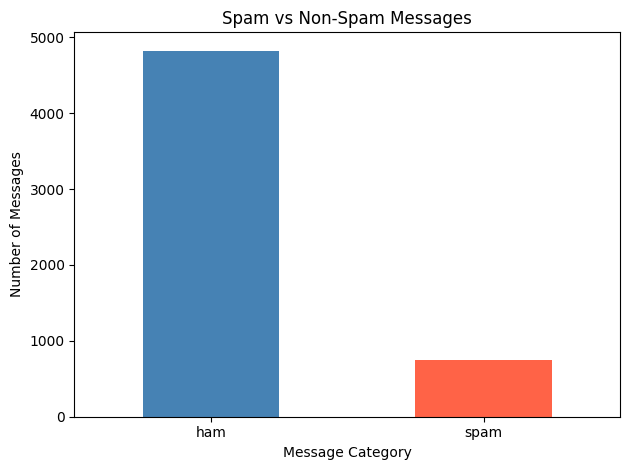

In [ ]:

import matplotlib.pyplot as plt

counts = df["Label"].value_counts()

counts.plot(kind="bar", color=["steelblue", "tomato"])

plt.title("Spam vs Non-Spam Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Separate messages and labels
X = df["Message"]
y = df["Label"]

# Split into training data and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Build the spam detection model
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

# Train the model
model.fit(X_train, y_train)

# Predict test messages
y_pred = model.predict(X_test)

print("Model training completed!")
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Model training completed!
Training messages: 4457
Testing messages: 1115


In [ ]:

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Model Accuracy: 96.05 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.70      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115


Confusion Matrix:
[[966   0]
 [ 44 105]]


In [ ]:

test_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hi, are we meeting at college tomorrow?",
    "URGENT! Claim your cash reward by clicking the link",
    "Please send me the assignment notes"
]

predictions = model.predict(test_messages)

for message, prediction in zip(test_messages, predictions):
    result = "SPAM" if prediction == "spam" else "NOT SPAM"

    print("Message:", message)
    print("Prediction:", result)
    print("-" * 50)


Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
--------------------------------------------------
Message: Hi, are we meeting at college tomorrow?
Prediction: NOT SPAM
--------------------------------------------------
Message: URGENT! Claim your cash reward by clicking the link
Prediction: SPAM
--------------------------------------------------
Message: Please send me the assignment notes
Prediction: NOT SPAM
--------------------------------------------------


In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Copy the original dataset
dataset_sheet = df.copy()
dataset_sheet.insert(
    0, "Record_ID", range(1, len(dataset_sheet) + 1)
)

# Create a sheet with actual and predicted labels
results_df = pd.DataFrame({
    "Message": X_test.reset_index(drop=True),
    "Actual_Label": y_test.reset_index(drop=True),
    "Predicted_Label": y_pred
})

results_df["Correct_Prediction"] = (
    results_df["Actual_Label"] == results_df["Predicted_Label"]
)

# Prepare summary data
summary_df = pd.DataFrame({
    "Category": ["Total Messages", "Spam Messages", "Non-Spam Messages"],
    "Count": [
        len(df),
        int((df["Label"] == "spam").sum()),
        int((df["Label"] == "ham").sum())
    ]
})

# Prepare model metrics
metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label="spam", zero_division=0),
        recall_score(y_test, y_pred, pos_label="spam", zero_division=0),
        f1_score(y_test, y_pred, pos_label="spam", zero_division=0)
    ]
})

# Export everything into one Excel workbook
output_file = "Spam_Email_Detection_Results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    dataset_sheet.to_excel(
        writer, sheet_name="Dataset", index=False
    )
    results_df.to_excel(
        writer, sheet_name="Predictions", index=False
    )
    summary_df.to_excel(
        writer, sheet_name="Summary", index=False
    )
    metrics_df.to_excel(
        writer, sheet_name="Model_Metrics", index=False
    )

print("Excel file created:", output_file)

# Download the Excel workbook to your computer
from google.colab import files
files.download(output_file)


Excel file created: Spam_Email_Detection_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>